# Klasyfikacja sygnalow EKG z CWT i 2D CNN (MIT-BIH)

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

from src.cwt import build_cwt_dataset_with_groups, plot_cwt_comparison
from src.cwt_models import build_cwt_2d_cnn
from src.cwt_training import compare_cwt_wavelets, plot_cwt_wavelet_confusion_matrices
from src.metadata import get_patient_statistics_table
from src.device import setup_accelerator_and_memory

setup_accelerator_and_memory()

{'gpu_available': False,
 'gpu_count': 0,
 'device_type': 'CPU',
 'mixed_precision': False}

### 1. Rozklad klas i pacjenci (MIT-BIH Arrhythmia Database)

In [2]:
cwt_records = ['100', '106', '109', '119']
stats_df = get_patient_statistics_table(cwt_records)
display(stats_df)

,ID,Grupa,Wiek,Plec,Stymulator,Norma (-1),Arytmia / Stym (+1),Razem,Udzial (+1)
0,100,Standard,69,M,Nie,2239,34,2273,1.5%
1,106,Standard,24,F,Nie,1507,520,2027,25.7%
2,109,Standard,64,M,Nie,2492,40,2532,1.6%
3,119,Standard,51,F,Nie,1543,444,1987,22.3%


### 2. Transformata falkowa CWT: Porownanie falek Morlet vs Mexican Hat

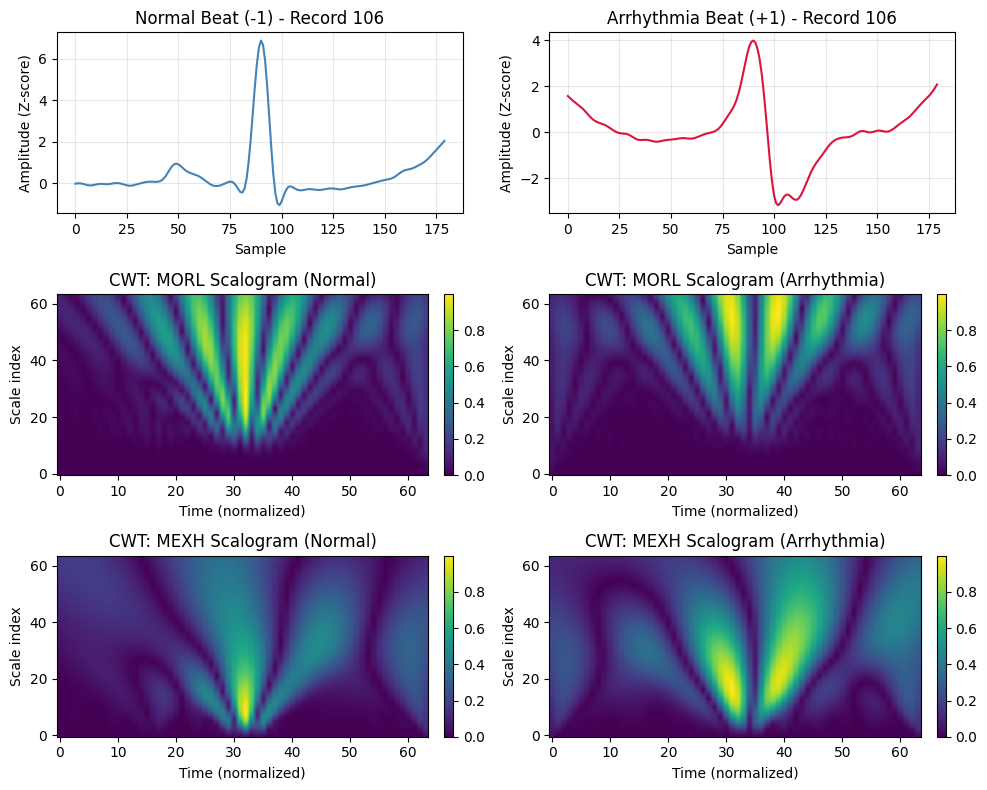

In [3]:
plot_cwt_comparison(record_id='106', wavelets=('morl', 'mexh'))

### 3. Architektura 2D CNN dla skalogramow czasowo-czestotliwosciowych

In [4]:
cwt_cnn_model = build_cwt_2d_cnn(input_shape=(32, 32, 1))
cwt_cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        65,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70,401 (275.00 KB)

 Trainable params: 70,401 (275.00 KB)

 Non-trainable params: 0 (0.00 B)

### 4. Trening i walidacja miedzyosobnicza GroupKFold dla falek MORL i MEXH

In [6]:
comparison_df, artifacts = compare_cwt_wavelets(
    record_ids=cwt_records, wavelets=['morl', 'mexh'], epochs=3, batch_size=64, max_beats_per_record=400
)
display(comparison_df)

,Falka (Wavelet),Model,Liczba Foldow,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),MCC (Absolute)
0,MORL,2D CNN (CWT),4,0.6969 (+/- 0.4091),0.7068 (+/- 0.4447),0.6962 (+/- 0.2375),0.5897 (+/- 0.3887),0.4377 (+/- 0.4489)
1,MEXH,2D CNN (CWT),4,0.7219 (+/- 0.3926),0.8443 (+/- 0.2026),0.7165 (+/- 0.2385),0.6174 (+/- 0.3782),0.4818 (+/- 0.4409)


### 5. Macierze pomylek dla falki Morlet oraz Mexican Hat

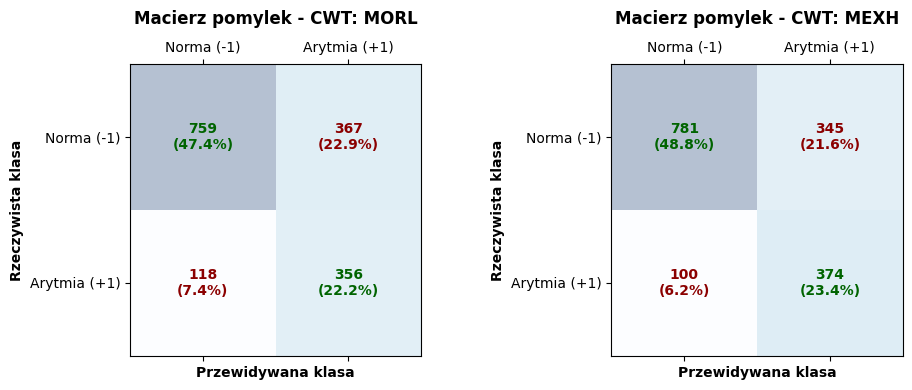

In [7]:
plot_cwt_wavelet_confusion_matrices(artifacts)